# Customer Churn Classification

**AI Engineer Internship Task 1**

This project explores the supplied customer dataset, prepares numerical and categorical features, trains classification models, compares them with cross-validation and a held-out test set, and demonstrates how to score a new customer.

> **Important data-quality note:** the supplied labels appear to have very weak relationships with the available features. The notebook reports measured performance honestly rather than forcing a high score.

## 1. Environment and imports
Run the notebook from this project folder so that `customer_churn_data.csv` is found.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import sklearn

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 3.1.1
scikit-learn: 1.9.1


## 2. Load and explore the data

In [2]:
DATA_PATH = "customer_churn_data.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())
print("\nData types and non-null counts:")
df.info()

Dataset shape: 5,880 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST0000,Male,0,No,Yes,23,No,No phone service,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer,49.85,1146.55,No
1,CUST0001,Female,0,Yes,No,43,No,No phone service,DSL,Yes,No,Yes,No,Yes,No,Month-to-month,No,Mailed check,100.70,4330.10,Yes
2,CUST0002,Male,1,No,No,51,Yes,No,DSL,No,Yes,Yes,Yes,No,No,One year,No,Electronic check,97.33,4963.83,Yes
3,CUST0003,Male,1,No,No,72,Yes,Yes,DSL,Yes,No,Yes,No,No,No,Month-to-month,No,Credit card,101.38,7299.36,No
4,CUST0004,Male,1,No,No,25,Yes,Yes,DSL,No,No,No,Yes,No,Yes,Month-to-month,No,Electronic check,52.22,1305.50,Yes



Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 5880 entries, 0 to 5879
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5880 non-null   str    
 1   gender            5880 non-null   str    
 2   SeniorCitizen     5880 non-null   int64  
 3   Partner           5880 non-null   str    
 4   Dependents        5880 non-null   str    
 5   tenure            5880 non-null   int64  
 6   PhoneService      5880 non-null   str    
 7   MultipleLines     5880 non-null   str    
 8   InternetService   5880 non-null   str    
 9   OnlineSecurity    5880 non-null   str    
 10  OnlineBackup      5880 non-null   str    
 11  DeviceProtection  5880 non-null   str    
 12  TechSupport       5880 non-null   str    
 13  StreamingTV       5880 non-null   str    
 14  StreamingMovies   5880 non-null   str    
 15  Contract          5880 non-null   str    
 16  PaperlessBilling  58

In [3]:
print("Missing values by column:")
display(df.isna().sum().to_frame("Missing values"))
print("Exact duplicate rows:", df.duplicated().sum())
if "customerID" in df.columns:
    print("Unique customer IDs:", df["customerID"].nunique())
print("\nTarget counts:")
display(df["Churn"].value_counts().rename_axis("Churn").to_frame("Customers"))
print("\nTarget percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2).rename("Percentage").to_frame())

Missing values by column:


,Missing values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Exact duplicate rows: 0
Unique customer IDs: 5880

Target counts:


,Customers
Churn,
No,2982
Yes,2898



Target percentages:


,Percentage
Churn,
No,50.71
Yes,49.29


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,5880.0,0.500680,0.500042,0.00,0.0000,1.000,1.0000,1.00
tenure,5880.0,36.549150,20.909674,1.00,18.0000,37.000,55.0000,72.00
MonthlyCharges,5880.0,70.157779,28.804615,20.00,45.7175,70.155,95.4575,119.99
TotalCharges,5880.0,2566.813165,1910.017743,20.03,1020.2175,2136.445,3767.6650,8589.60


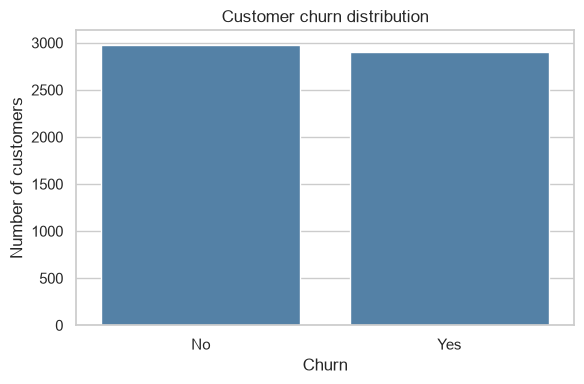

In [4]:
numeric_preview = df.select_dtypes(include=np.number)
display(numeric_preview.describe().T)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], color="steelblue")
plt.title("Customer churn distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

## 3. Data preparation
`customerID` is an identifier, so it is excluded from model inputs. The target is mapped to 0/1. Missing numeric and categorical values are imputed inside the preprocessing pipeline, which prevents information from the test set leaking into training.

In [5]:
required_target = "Churn"
if required_target not in df.columns:
    raise ValueError("The dataset must contain a 'Churn' target column.")

data = df.drop(columns=["customerID"], errors="ignore").copy()
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})
if data["Churn"].isna().any():
    raise ValueError("Unexpected target labels found. Expected only 'Yes' and 'No'.")

X = data.drop(columns="Churn")
y = data["Churn"].astype(int)
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

print("Feature count:", X.shape[1])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Churn rate: {:.2f}%".format(y.mean() * 100))

Feature count: 19
Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Churn rate: 49.29%


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training churn rate: {:.2f}%".format(y_train.mean() * 100))
print("Test churn rate: {:.2f}%".format(y_test.mean() * 100))

Training rows: 4704
Test rows: 1176
Training churn rate: 49.28%
Test churn rate: 49.32%


## 4. Train and compare classification models
The comparison includes a dummy baseline and three standard classifiers. The dummy model predicts the most frequent class and provides a useful reference point.

In [7]:
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=250, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", estimator)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({"Model": name, **{metric: scores[f"test_{metric}"].mean() for metric in scoring}})

cv_results = pd.DataFrame(cv_rows).set_index("Model").sort_values("roc_auc", ascending=False)
display(cv_results.round(4))

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Random Forest,0.5162,0.5097,0.5026,0.5059,0.5097
Dummy baseline,0.5072,0.0000,0.0000,0.0000,0.5000
Gradient Boosting,0.4887,0.4801,0.4586,0.4690,0.4969
Logistic Regression,0.4934,0.4866,0.5039,0.4949,0.4869


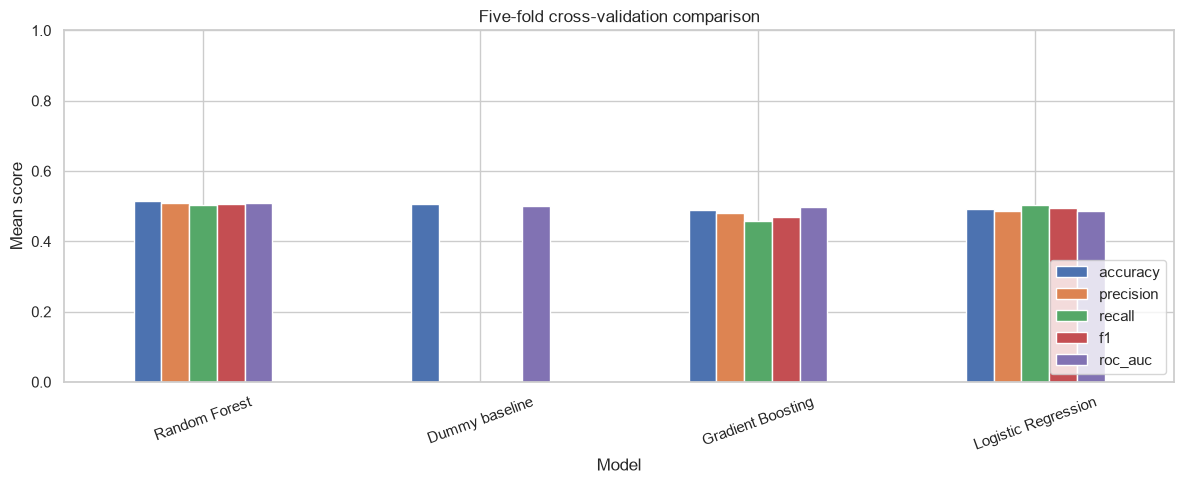

In [8]:
ax = cv_results[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1), rot=20
)
ax.set_title("Five-fold cross-validation comparison")
ax.set_ylabel("Mean score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Evaluate on the held-out test set

In [9]:
trained_models = {}
test_rows = []

for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", estimator)])
    pipe.fit(X_train, y_train)
    trained_models[name] = pipe
    predictions = pipe.predict(X_test)
    probabilities = pipe.predict_proba(X_test)[:, 1]
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

test_results = pd.DataFrame(test_rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(test_results.round(4))
candidate_models = [name for name in trained_models if name != "Dummy baseline"]
best_model_name = test_results.loc[candidate_models, "ROC-AUC"].idxmax()
best_pipeline = trained_models[best_model_name]
print("Best model by held-out ROC-AUC:", best_model_name)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.5102,0.5034,0.5172,0.5102,0.5028
Dummy baseline,0.5068,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.4804,0.4731,0.4707,0.4719,0.4748
Gradient Boosting,0.4804,0.4721,0.4517,0.4617,0.4634


Best model by held-out ROC-AUC: Random Forest


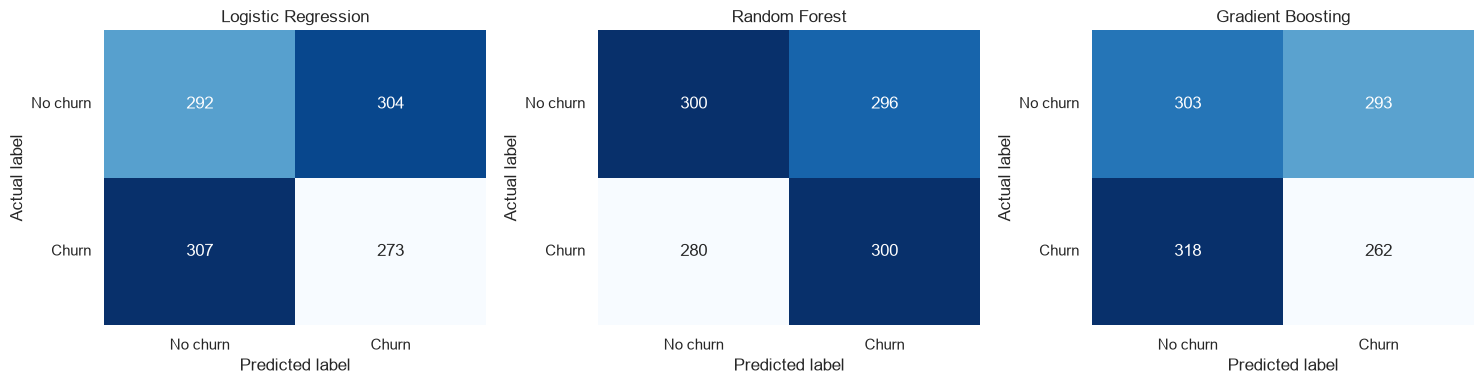

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest", "Gradient Boosting"]):
    pred = trained_models[name].predict(X_test)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_xticklabels(["No churn", "Churn"])
    ax.set_yticklabels(["No churn", "Churn"], rotation=0)
plt.tight_layout()
plt.show()

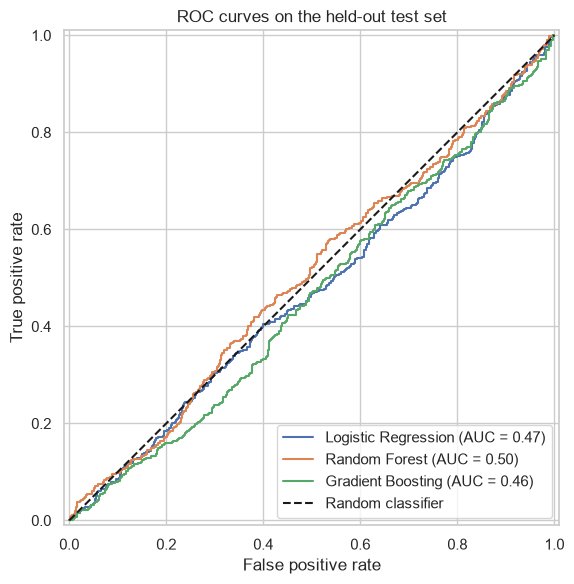

In [11]:
plt.figure(figsize=(8, 6))
for name in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
    RocCurveDisplay.from_estimator(trained_models[name], X_test, y_test, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.title("ROC curves on the held-out test set")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("models_performance_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

In [12]:
print("Classification report for:", best_model_name)
print(classification_report(y_test, best_pipeline.predict(X_test), target_names=["No churn", "Churn"], zero_division=0))

print("ROC-AUC interpretation:")
best_auc = test_results.loc[best_model_name, "ROC-AUC"]
if best_auc > 0.60:
    print("The selected model shows some ability to rank churn risk, but further validation is still needed.")
elif best_auc >= 0.45:
    print("Performance is close to the 0.50 random-ranking baseline. The available features provide little demonstrated predictive signal.")
else:
    print("Performance is below the random-ranking baseline. Check target encoding, data generation and feature/label alignment.")

Classification report for: Random Forest
              precision    recall  f1-score   support

    No churn       0.52      0.50      0.51       596
       Churn       0.50      0.52      0.51       580

    accuracy                           0.51      1176
   macro avg       0.51      0.51      0.51      1176
weighted avg       0.51      0.51      0.51      1176

ROC-AUC interpretation:
Performance is close to the 0.50 random-ranking baseline. The available features provide little demonstrated predictive signal.


## 6. Feature importance (when supported)

,Importance
numeric__TotalCharges,0.145121
numeric__MonthlyCharges,0.144437
numeric__tenure,0.126246
numeric__SeniorCitizen,0.027954
categorical__PaperlessBilling_No,0.020791
categorical__Dependents_Yes,0.020271
categorical__PaperlessBilling_Yes,0.020214
categorical__Contract_Month-to-month,0.019752
categorical__Contract_One year,0.019546
categorical__Contract_Two year,0.019439


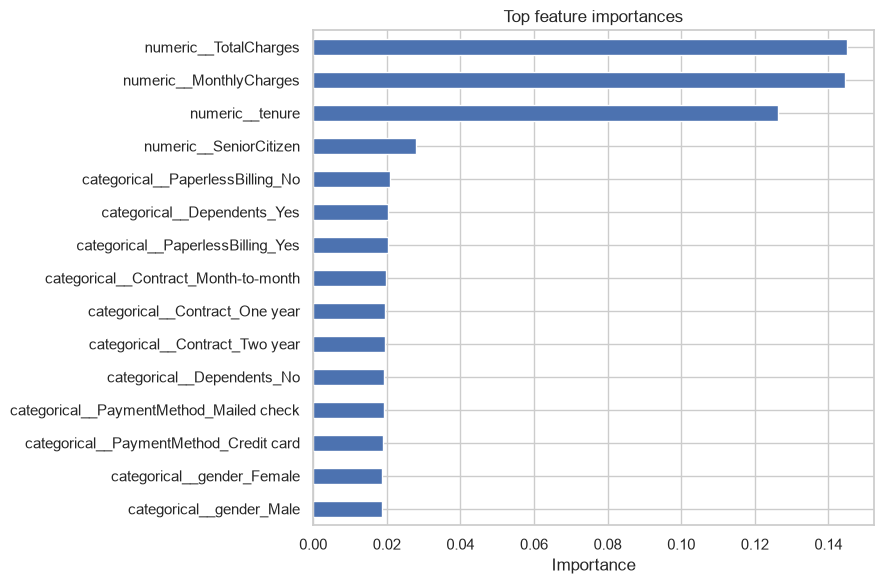

In [13]:
classifier = best_pipeline.named_steps["classifier"]
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()

if hasattr(classifier, "feature_importances_"):
    importance = pd.Series(classifier.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
    display(importance.to_frame("Importance"))
    importance.sort_values().plot(kind="barh", figsize=(9, 6), title="Top feature importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
elif hasattr(classifier, "coef_"):
    coefficients = pd.Series(np.abs(classifier.coef_[0]), index=feature_names).sort_values(ascending=False).head(15)
    display(coefficients.to_frame("Absolute coefficient"))
else:
    print("This model does not expose built-in feature importance.")

## 7. Predict churn for new customers
The function below accepts a DataFrame with the same input columns as the training data. The trained pipeline handles encoding and scaling automatically.

In [14]:
def predict_churn(customer_data, model_pipeline=best_pipeline):
    """Return the predicted class, churn probability and a simple risk band."""
    if not isinstance(customer_data, pd.DataFrame):
        customer_data = pd.DataFrame(customer_data)
    missing_columns = set(X.columns) - set(customer_data.columns)
    extra_columns = set(customer_data.columns) - set(X.columns)
    if missing_columns or extra_columns:
        raise ValueError(f"Input columns mismatch. Missing: {sorted(missing_columns)}; extra: {sorted(extra_columns)}")
    customer_data = customer_data[X.columns]
    probabilities = model_pipeline.predict_proba(customer_data)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    results = []
    for pred, prob in zip(predictions, probabilities):
        results.append({
            "prediction": "Likely to churn" if pred == 1 else "Likely to stay",
            "churn_probability": float(prob),
            "risk_band": "High" if prob >= 0.70 else "Medium" if prob >= 0.40 else "Low"
        })
    return pd.DataFrame(results)

example_customer = X.iloc[[0]].copy()
display(example_customer)
display(predict_churn(example_customer))

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Male,0,No,Yes,23,No,No phone service,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer,49.85,1146.55


,prediction,churn_probability,risk_band
0,Likely to stay,0.289599,Low


In [15]:
def interactive_prediction(model_pipeline=best_pipeline):
    profile = X.mode(dropna=True).iloc[0].to_dict()

    profile["tenure"] = int(input("Tenure in months (1-72): "))
    profile["MonthlyCharges"] = float(input("Monthly charges: "))
    profile["Contract"] = input(
        "Contract (Month-to-month, One year, Two year): "
    ).strip()

    profile["TotalCharges"] = (
        profile["tenure"] * profile["MonthlyCharges"]
    )

    customer = pd.DataFrame([profile], columns=X.columns)
    result = predict_churn(customer, model_pipeline).iloc[0]

    print("Prediction:", result["prediction"])
    print("Estimated churn probability: {:.2%}".format(
        result["churn_probability"]
    ))
    print("Risk band:", result["risk_band"])

In [16]:
interactive_prediction()

Tenure in months (1-72):  2
Monthly charges:  95
Contract (Month-to-month, One year, Two year):  Month-to-month


Prediction: Likely to stay
Estimated churn probability: 42.92%
Risk band: Medium


## 8. Conclusions and limitations

In [17]:
print(f"Dataset: {len(df):,} customers and {X.shape[1]} input features")
print(f"Observed churn rate: {y.mean():.2%}")
print("Selected model:", best_model_name)
print("Held-out ROC-AUC: {:.4f}".format(best_auc))
print("\nInterpretation:")
if abs(best_auc - 0.5) <= 0.05:
    print("The best model is close to chance-level ranking on this split. The current dataset does not support a dependable churn prediction claim.")
else:
    print("The best model differs from the random-ranking baseline on this split; validate on fresh, representative data before deployment.")
print("\nLimitations:")
print("- Results depend on the quality and representativeness of the supplied data.")
print("- A single train/test split is not proof of real-world performance.")
print("- Risk bands are illustrative probability ranges, not business-approved thresholds.")
print("- Investigate how the churn labels were generated and add relevant customer-behaviour history before deployment.")

Dataset: 5,880 customers and 19 input features
Observed churn rate: 49.29%
Selected model: Random Forest
Held-out ROC-AUC: 0.5028

Interpretation:
The best model is close to chance-level ranking on this split. The current dataset does not support a dependable churn prediction claim.

Limitations:
- Results depend on the quality and representativeness of the supplied data.
- A single train/test split is not proof of real-world performance.
- Risk bands are illustrative probability ranges, not business-approved thresholds.
- Investigate how the churn labels were generated and add relevant customer-behaviour history before deployment.


## Project deliverables
- `Customer_Churn_Classification.ipynb`: complete, executable analysis and modelling workflow.
- `customer_churn_data.csv`: supplied dataset.
- `models_performance_comparison.png`: ROC curve comparison generated by the notebook.
- `requirements.txt`: Python dependencies.
- `README.md`: setup and execution instructions.

Run all notebook cells from top to bottom. The interactive prompt is intentionally not launched automatically, so **Run All** completes without waiting for keyboard input.